# 12. Frequency Distribution in NLP

## Learning objectives
By the end of this notebook, you will be able to:
- Explain what a frequency distribution is.
- Count words and inspect the most common items.
- Compare word frequencies across a text.
- Normalize text before counting and understand why preprocessing matters.
- Use NLTK's `FreqDist` and visualize a small set of frequent words.

## 1. What is a frequency distribution?

A **frequency distribution** records how often each item appears in a collection. In NLP, the items are often words or tokens. Frequency counts can help us explore a document, identify repeated terms, and prepare features for later text-processing tasks.

The examples below use short, built-in text so the notebook can be run without downloading a corpus.


## 2. Count tokens with Python

Start with a small sentence. For this example, whitespace splitting is enough, although it does not separate punctuation perfectly.


In [1]:
text = "NLP helps computers process language. Language data helps NLP systems."

tokens = text.lower().split()

print(tokens)
print("Number of tokens:", len(tokens))
print("Number of unique tokens:", len(set(tokens)))

['nlp', 'helps', 'computers', 'process', 'language.', 'language', 'data', 'helps', 'nlp', 'systems.']
Number of tokens: 10
Number of unique tokens: 8


Notice that `language.` and `language` are treated as different tokens because punctuation is still attached. The next section shows a simple cleanup step.


## 3. Normalize text before counting

Lowercasing makes `NLP` and `nlp` equivalent. Removing punctuation helps avoid counting `language` and `language.` separately. This simple regular-expression approach is useful for learning; production preprocessing may need language-specific rules.


In [2]:
import re
from collections import Counter

text = "NLP helps computers process language. Language data helps NLP systems!"

clean_text = re.sub(r"[^\w\s]", "", text.lower())
tokens = clean_text.split()

print("Clean text:", clean_text)
print("Tokens:", tokens)

counts = Counter(tokens)
print("\\nWord counts:")
print(counts)

Clean text: nlp helps computers process language language data helps nlp systems
Tokens: ['nlp', 'helps', 'computers', 'process', 'language', 'language', 'data', 'helps', 'nlp', 'systems']
\nWord counts:
Counter({'nlp': 2, 'helps': 2, 'language': 2, 'computers': 1, 'process': 1, 'data': 1, 'systems': 1})


## 4. Inspect the most common words

`Counter` is a standard Python tool for counting hashable items. Its `most_common()` method returns the items with the highest counts first.


In [3]:
print("Most common 3 tokens:")
for word, count in counts.most_common(3):
    print(f"{word}: {count}")

Most common 3 tokens:
nlp: 2
helps: 2
language: 2


## 5. Use NLTK's `FreqDist`

NLTK provides `FreqDist`, a frequency-distribution class with methods for counting and inspecting tokens. If NLTK is not installed in the active environment, install it in your terminal or notebook environment first.


In [4]:
from nltk import FreqDist

fdist = FreqDist(tokens)

print("Total tokens:", fdist.N())
print("Unique tokens:", fdist.B())
print("Count of 'nlp':", fdist["nlp"])
print("Most common tokens:", fdist.most_common(5))

Total tokens: 10
Unique tokens: 7
Count of 'nlp': 2
Most common tokens: [('nlp', 2), ('helps', 2), ('language', 2), ('computers', 1), ('process', 1)]


- `N()` returns the total number of token occurrences.
- `B()` returns the number of distinct tokens (the vocabulary size).
- `fdist[word]` returns the frequency of a token.
- `most_common(n)` returns the `n` most frequent tokens.


## 6. Work with a longer example

A tiny text can have many ties. Use a longer sample to see a more informative distribution.


In [5]:
sample_text = '''
Natural language processing helps computers work with human language.
Language processing includes tokenization, normalization, and analysis.
Computers can analyze words, count words, and compare word frequencies.
Text analysis is a useful first step in many NLP projects.
'''

sample_clean = re.sub(r"[^\w\s]", "", sample_text.lower())
sample_tokens = sample_clean.split()
sample_fdist = FreqDist(sample_tokens)

print("Total tokens:", sample_fdist.N())
print("Unique tokens:", sample_fdist.B())
print("\\nTop 10 tokens:")
for word, count in sample_fdist.most_common(10):
    print(f"{word:15} {count}")

Total tokens: 37
Unique tokens: 30
\nTop 10 tokens:
language        3
processing      2
computers       2
and             2
analysis        2
words           2
natural         1
helps           1
work            1
with            1


## 7. Plot frequent words

NLTK's `plot()` can display the cumulative counts of the most common tokens. Plotting requires a graphical backend; if a plot does not appear in Jupyter, try `%matplotlib inline` in a separate cell.


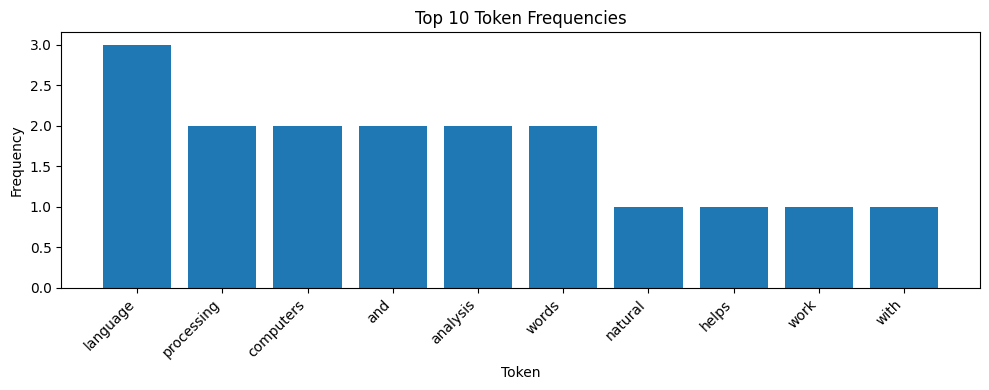

In [6]:
import matplotlib.pyplot as plt

top_items = sample_fdist.most_common(10)
words = [word for word, count in top_items]
frequencies = [count for word, count in top_items]

plt.figure(figsize=(10, 4))
plt.bar(words, frequencies)
plt.xlabel("Token")
plt.ylabel("Frequency")
plt.title("Top 10 Token Frequencies")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 8. Frequency distribution by sentence

Frequency counts can be calculated for different parts of a document. This example compares how often the token `language` appears in each sentence.


In [7]:
sentences = [
    "Language technology is growing.",
    "Natural language processing studies language.",
    "Computers can process text."
]

for index, sentence in enumerate(sentences, start=1):
    sentence_tokens = re.sub(r"[^\w\s]", "", sentence.lower()).split()
    sentence_fdist = FreqDist(sentence_tokens)
    print(f"Sentence {index}: 'language' appears {sentence_fdist['language']} time(s)")

Sentence 1: 'language' appears 1 time(s)
Sentence 2: 'language' appears 2 time(s)
Sentence 3: 'language' appears 0 time(s)


## 9. Important limitations

- **Frequency is not meaning.** A common word is not necessarily important to the meaning of a document.
- **Tokenization matters.** Splitting only on whitespace may leave punctuation attached and does not handle every language well.
- **Normalization changes results.** Lowercasing, stemming, lemmatization, and stop-word removal each affect counts.
- **Corpus size matters.** Compare counts carefully when documents have different lengths; relative frequency may be more useful.
- **Language matters.** Persian, English, and other languages may require different tokenization and normalization approaches.


## 10. Exercises

1. Change `text` and compare the token count with the number of unique tokens.
2. Create a sentence that contains `NLP`, `nlp`, and `Nlp`. Count the tokens before and after lowercasing.
3. Print the 5 least common tokens in `sample_fdist`. (Hint: inspect `sample_fdist.items()` and sort by count.)
4. Calculate the relative frequency of each token by dividing its count by `sample_fdist.N()`.
5. Try a Persian sentence and discuss what the simple regular expression does to its characters.

## Summary

A frequency distribution counts token occurrences and helps summarize text. Python's `Counter` and NLTK's `FreqDist` provide convenient ways to count, rank, and inspect words. The quality of the result depends on tokenization and preprocessing choices.
